In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

from google.colab import files
uploaded = files.upload()

df = pd.read_csv("Bengaluru_House_Data.csv")
df.head()


Saving Bengaluru_House_Data.csv to Bengaluru_House_Data.csv


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [2]:
# Drop less relevant or missing-heavy columns
df.drop(['society', 'availability'], axis=1, inplace=True)

# Fill missing values
df['bath'].fillna(df['bath'].median(), inplace=True)
df['balcony'].fillna(0, inplace=True)
df.dropna(inplace=True)

# Extract BHK from size
df['bhk'] = df['size'].str.extract('(\d+)').astype(float)

# Convert sqft ranges to mean value
def convert_sqft(x):
    if '-' in x:
        tokens = x.split('-')
        return (float(tokens[0]) + float(tokens[1])) / 2
    try:
        return float(x)
    except:
        return None

df['total_sqft'] = df['total_sqft'].apply(convert_sqft)
df.dropna(subset=['total_sqft'], inplace=True)
df['price_per_sqft'] = df['price'] * 100000 / df['total_sqft']


/tmp/ipython-input-2-1449995471.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['bath'].fillna(df['bath'].median(), inplace=True)
/tmp/ipython-input-2-1449995471.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)'

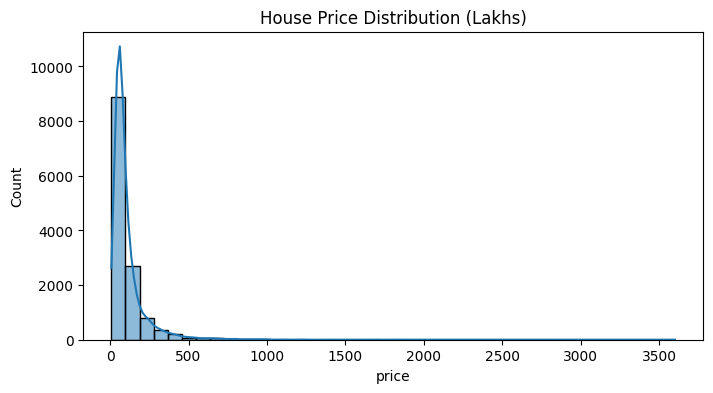

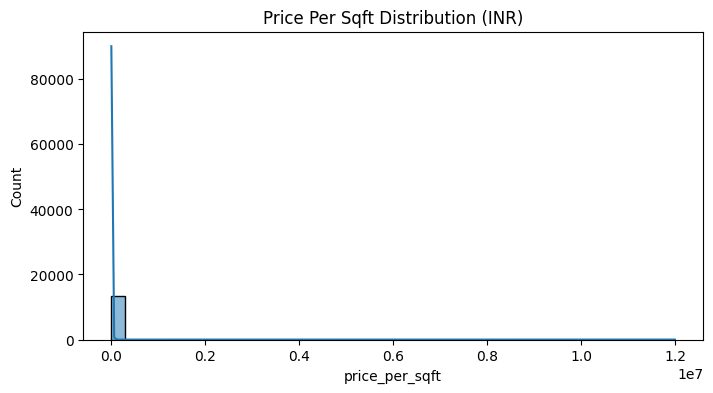

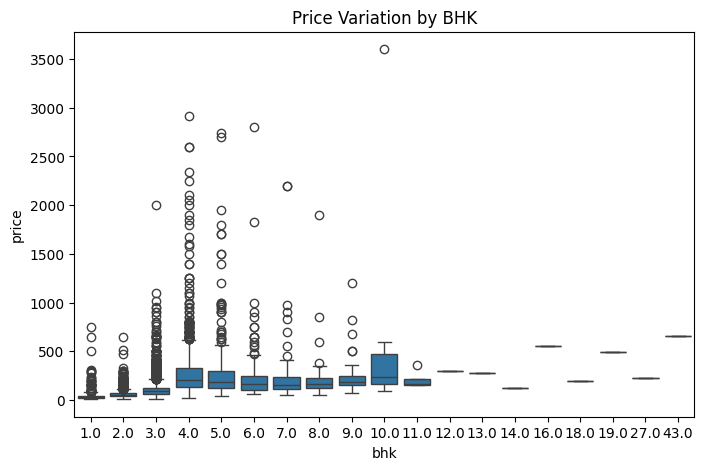

In [3]:
# Price distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['price'], kde=True, bins=40)
plt.title("House Price Distribution (Lakhs)")
plt.show()

# Price per sqft
plt.figure(figsize=(8, 4))
sns.histplot(df['price_per_sqft'], kde=True, bins=40)
plt.title("Price Per Sqft Distribution (INR)")
plt.show()

# BHK vs Price
plt.figure(figsize=(8, 5))
sns.boxplot(x='bhk', y='price', data=df)
plt.title("Price Variation by BHK")
plt.show()


In [4]:
# One-hot encode area_type
dummies = pd.get_dummies(df['area_type'], drop_first=True)

final_df = pd.concat([df[['total_sqft', 'bath', 'balcony', 'bhk', 'price']], dummies], axis=1)

X = final_df.drop('price', axis=1)
y = final_df['price']


In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)


In [6]:
print(f"R² Score: {r2_score(y_test, y_pred):.2f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f} Lakhs")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")


R² Score: 0.47
MAE: 45.06 Lakhs
MSE: 12035.51


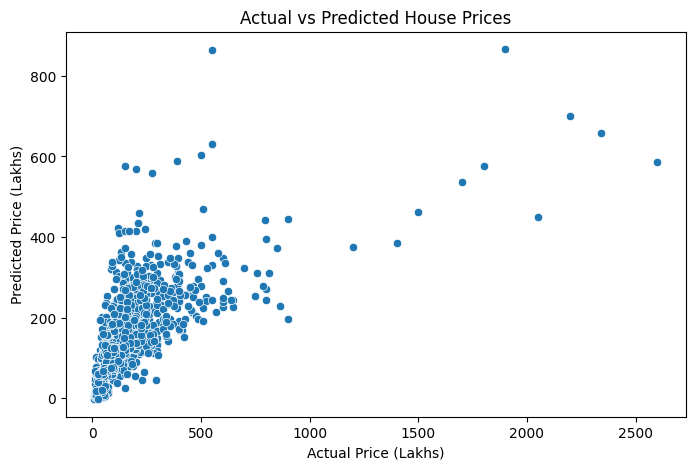

In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_test, y=y_pred)
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted House Prices")
plt.show()
